# Etapa 2 - Modelo Predictivo Linear Regression

Modelo de referencia (*baseline*) para validar que el `RandomForestRegressor` es realmente la mejor alternativa para la misma pregunta de negocio: *¿qué tipo de café tendrá la mayor rentabilidad esperada durante el próximo mes?* Es un modelo simple, rápido y sin hiperparámetros. Usa el dataset procesado y la misma partición cronológica del Random Forest, por lo que `modelo_random_forest.ipynb` debe ejecutarse antes. **No lo reemplaza**: la comparación final y la selección del modelo están en ese notebook.

## Carga de librerías

In [1]:
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def es(valor, decimales=0, porcentaje=False):
    """Formato numérico en español: 1.234,5 y 12,3 %."""
    if porcentaje:
        valor *= 100
    texto = f"{valor:,.{decimales}f}".replace(",", "_").replace(".", ",").replace("_", ".")
    return texto + (" %" if porcentaje else "")


# Mismos parámetros que el notebook del Random Forest
TEST_SIZE = 0.20
HORIZONTE_DIAS = 30    # "próximo mes"
RUTA_MODELO = "modelo"
RUTA_DATASET = os.path.join("datos", "dataset_procesado.csv")

## Carga de datos

In [2]:
# Dataset procesado que genera modelo_random_forest.ipynb (una fila por café y fecha de corte)
if not os.path.exists(RUTA_DATASET):
    raise FileNotFoundError(f"No existe {RUTA_DATASET}. Ejecutá antes modelo_random_forest.ipynb.")
dataset = pd.read_csv(RUTA_DATASET, parse_dates=["fecha_ref"], float_precision="round_trip")

X = dataset.drop(columns=["cafe", "fecha_ref", "y"])      # variables predictoras (mismo orden que el Random Forest)
y = dataset["y"]                                          # rentabilidad de los 30 días siguientes
print(f"{len(dataset)} filas ({dataset['fecha_ref'].nunique()} fechas de corte x {dataset['cafe'].nunique()} cafés) | {X.shape[1]} variables predictoras")

376 filas (47 fechas de corte x 8 cafés) | 18 variables predictoras


## Partición de datos

Partición **cronológica** (`train_test_split` sin mezclar), con los mismos parámetros del Random Forest: se entrena con el pasado y se evalúa con el período más reciente, descartando de entrenamiento el último mes previo a la prueba para que ningún objetivo se superponga con el período evaluado.

In [3]:
fechas = dataset["fecha_ref"].drop_duplicates().sort_values().reset_index(drop=True)
f_train, f_test = train_test_split(fechas, test_size=TEST_SIZE, shuffle=False)
f_train = f_train[f_train <= f_test.iloc[0] - pd.Timedelta(days=HORIZONTE_DIAS)]    # separación de 30 días

es_train, es_test = dataset["fecha_ref"].isin(f_train), dataset["fecha_ref"].isin(f_test)
X_train, y_train = X[es_train], y[es_train]
X_test, y_test = X[es_test], y[es_test]
test = dataset.loc[es_test, ["fecha_ref", "cafe", "y"]].copy()

print(f"Entrenamiento: {X_train.shape} ({f_train.min().date()} a {f_train.max().date()})")
print(f"Prueba:        {X_test.shape} ({f_test.min().date()} a {f_test.max().date()})")

Entrenamiento: (264, 18) (2024-03-30 a 2024-11-09)
Prueba:        (80, 18) (2024-12-14 a 2025-02-15)


## Entrenamiento

`LinearRegression()` sin parámetros. Los tiempos son la mediana de varias ejecuciones, con la misma medición usada para el Random Forest.

In [4]:
def medir_tiempo(funcion, repeticiones=5):
    """Ejecuta `funcion` varias veces y devuelve (último resultado, mediana de segundos)."""
    duraciones = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        resultado = funcion()
        duraciones.append(time.perf_counter() - inicio)
    return resultado, float(np.median(duraciones))


modelo_lr, t_entrenamiento = medir_tiempo(lambda: LinearRegression().fit(X_train, y_train), repeticiones=5)
pred_test, t_prediccion = medir_tiempo(lambda: modelo_lr.predict(X_test), repeticiones=20)
pred_train = modelo_lr.predict(X_train)
test["pred_lr"] = pred_test

print(f"Entrenamiento: {t_entrenamiento:.4f} s | predicción: {t_prediccion * 1000:.2f} ms | {len(pred_test)} predicciones de prueba")

Entrenamiento: 0.0026 s | predicción: 0.93 ms | 80 predicciones de prueba


## Evaluación del modelo

,MAE,RMSE,R²
Linear Regression (prueba),446.281,710.123,0.310
Linear Regression (entrenamiento),289.268,389.732,0.793


,Spearman,Top 1,Top 3
Linear Regression,0.69,0.1,0.6


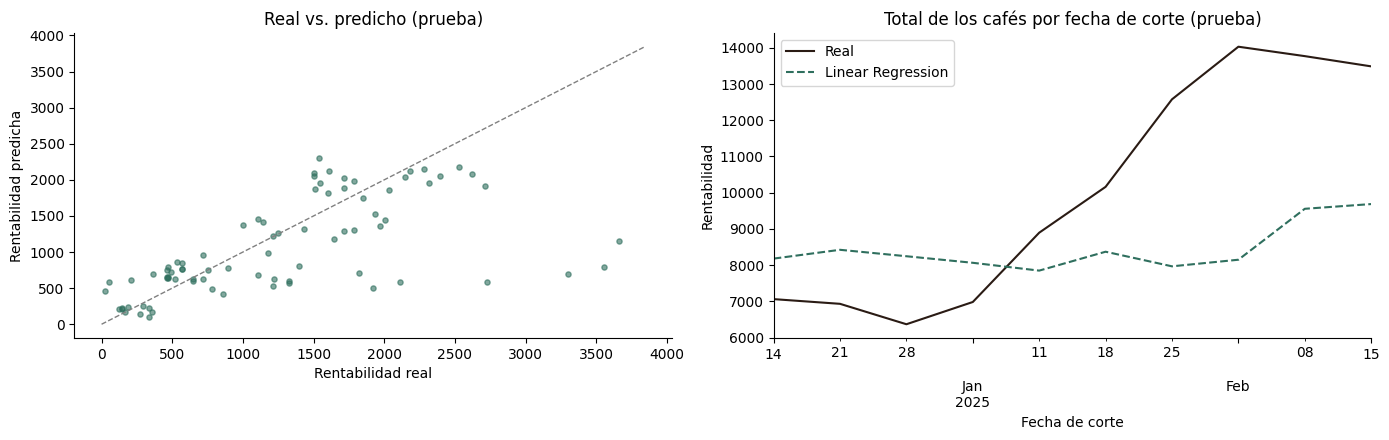

In [5]:
def calcular_metricas(real, pred):
    return {"MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "R²": r2_score(real, pred)}


def evaluar_ranking(datos, columna_pred):
    """Por fecha de corte: ¿el modelo ordena los cafés como ocurrió en la realidad?"""
    spearman, acierta_1, acierta_3 = [], [], []
    for _, g in datos.groupby("fecha_ref"):
        orden = g.sort_values(columna_pred, ascending=False)["cafe"].tolist()
        mejor_real = g.loc[g["y"].idxmax(), "cafe"]
        spearman.append(spearmanr(g[columna_pred], g["y"])[0])
        acierta_1.append(orden[0] == mejor_real)
        acierta_3.append(mejor_real in orden[:3])
    return {"Spearman": np.nanmean(spearman), "Top 1": np.mean(acierta_1), "Top 3": np.mean(acierta_3)}


m_lr = calcular_metricas(y_test, pred_test)
m_train = calcular_metricas(y_train, pred_train)
rk_lr = evaluar_ranking(test, "pred_lr")

display(pd.DataFrame({"Linear Regression (prueba)": m_lr, "Linear Regression (entrenamiento)": m_train}).T.round(3))
display(pd.DataFrame({"Linear Regression": rk_lr}).T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(test["y"], test["pred_lr"], s=14, alpha=.6, color="#2f6f5e")
limite = [min(0, test["pred_lr"].min()), max(test["y"].max(), test["pred_lr"].max()) * 1.05]
axes[0].plot(limite, limite, color="gray", ls="--", lw=1)
axes[0].set(title="Real vs. predicho (prueba)", xlabel="Rentabilidad real", ylabel="Rentabilidad predicha")

por_fecha = test.groupby("fecha_ref")[["y", "pred_lr"]].sum()
por_fecha.plot(ax=axes[1], style=["-", "--"], color=["#2a1b14", "#2f6f5e"])
axes[1].legend(["Real", "Linear Regression"])
axes[1].set(title="Total de los cafés por fecha de corte (prueba)", xlabel="Fecha de corte", ylabel="Rentabilidad")
plt.tight_layout(); plt.show()

In [6]:
sesgo = (test["pred_lr"] - test["y"]).mean()
display(Markdown(f'''
- **Error típico (MAE):** {es(m_lr["MAE"])} unidades monetarias por café y mes ({es(m_lr["MAE"] / test["y"].mean(), 0, True)} de la rentabilidad media observada en prueba); RMSE {es(m_lr["RMSE"])}.
- **R²:** {es(m_lr["R²"], 2)} en prueba frente a {es(m_train["R²"], 2)} en entrenamiento. En el período más reciente el modelo {"subestima" if sesgo < 0 else "sobreestima"} en promedio {es(abs(sesgo))} unidades por café.
- **Ordenamiento de cafés:** correlación de Spearman media de {es(rk_lr["Spearman"], 2)}; el café realmente más rentable fue su primera opción en el {es(rk_lr["Top 1"], 0, True)} de las fechas de corte y quedó entre las 3 primeras en el {es(rk_lr["Top 3"], 0, True)}.
- **Tiempos:** entrenamiento {es(t_entrenamiento, 3)} s y predicción {es(t_prediccion * 1000, 1)} ms.
'''))


- **Error típico (MAE):** 446 unidades monetarias por café y mes (36 % de la rentabilidad media observada en prueba); RMSE 710.
- **R²:** 0,31 en prueba frente a 0,79 en entrenamiento. En el período más reciente el modelo subestima en promedio 197 unidades por café.
- **Ordenamiento de cafés:** correlación de Spearman media de 0,69; el café realmente más rentable fue su primera opción en el 10 % de las fechas de corte y quedó entre las 3 primeras en el 60 %.
- **Tiempos:** entrenamiento 0,003 s y predicción 0,9 ms.


## Exportación

In [7]:
def cargar_modelo(ruta=RUTA_MODELO):
    """Carga la regresión lineal guardada."""
    return joblib.load(os.path.join(ruta, "linear_regression_model.joblib"))


os.makedirs(RUTA_MODELO, exist_ok=True)
joblib.dump(modelo_lr, os.path.join(RUTA_MODELO, "linear_regression_model.joblib"))

# Comprobación: el modelo recargado reproduce las predicciones de prueba
assert np.allclose(cargar_modelo().predict(X_test), pred_test)
print("Modelo guardado en:", os.path.join(RUTA_MODELO, "linear_regression_model.joblib"))

Modelo guardado en: modelo\linear_regression_model.joblib
